In [1]:
# needed when using ssh connection (?)
#%pip install tensorboard
#%pip install numpy
#%pip install torch
#%pip install matplotlib
#%pip install os

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.utils.tensorboard import SummaryWriter

In [3]:
cwd = os.getcwd()

ssh_connected = 1 # change to 1 if connected to supercomputer

if ssh_connected == 0:
    num_csvs = len(os.listdir("C:\\Users\\seanf\\OneDrive\\Documents\\Master's Files\\2nd Year\\Eclipsing Binaries\\Data\\ELISa lightcurve data"))
elif ssh_connected ==1:
    num_csvs = len(os.listdir("/home/astrouser/sean/Eclipsing Binaries/Data/ELISa lightcurve data"))
    
fluxes_array = np.empty((0, 100))  # initialize fluxes_array to empty, will be replaced with first light curve
phases_array = np.empty((0,100)) # same for phases 

EB_labels = np.loadtxt(os.path.join(cwd, "Data", "ELISa lightcurve data", "_labels.csv"), delimiter=',', usecols=0)
labels = np.array([]) 
fluxes = np.array([])
phases = np.array([])
param_names = ["T_ratio", "T1", "q", "m1", "period", "Omega1", "Omega2", "e"]
    
T1 = []     # set empty lists for parameters
T_ratio = []
q = []
m1 = []
period = []
Omega1 = []
Omega2 = []
e = []



params_1000 = {} # create empty dictionary for parameter list contianing 1000 values

for name in param_names: # loop through parameter names, adding their values to their name in the dictionary
    params_1000[name] = np.loadtxt(
        os.path.join(cwd, "Data", "ELISa synthetic parameters", f"{name}.csv"),
        delimiter=',',
        skiprows=0
    )

params = {} # create empty dict for correct number of param values

for name in param_names:
    # give empty dictionary correct keys
    params[name]=[]



# looping through each light curve csv file, adding them all to one 2d array of dimensions (num_csvs x 100)
for i in range(0, 4*num_csvs): # using 4 * num_csvs as csvs (currently) go from 1-999, many are missing, so this ensures we get all files 
    data_path = os.path.join(cwd, "Data", "ELISa lightcurve data", f"{i} lightcurve.csv")
    if os.path.exists(data_path): # only loads file if a lightcurve with that number exists, otherwise skips to next iteration
        data = np.loadtxt(data_path, delimiter=',', skiprows=1)
        phases = data[:, 0]
        fluxes = data[:, 1]
        label = EB_labels[i]  # get the corresponding label for the light curve. 
        labels = np.append(labels, label)


        for name in param_names:
            # insert only the parameters of the systems that are used into the new one - so that the system number for parameters matches with fluxes.
            params[name].append(params_1000[name][i])


        if fluxes_array.size < 1: # set up array with the first light curve. Will only trigger on first iteration due to np.empty
            fluxes_array = fluxes
        else: # add the next light curve to a 2d array of light curves
            fluxes_array = np.vstack((fluxes_array, fluxes))

        if phases_array.size < 1: # set up first phases into phases_array
            phases_array = phases
        else: # stack the next set of phases into a new line in the 2d array of phases
            phases_array = np.vstack((phases_array, phases))

    else:
        continue



In [4]:
# creating phase offset parameter, intended to model the synthetic data more as realistic data, and to be predicted as a parameter in itself
print(phases_array.shape)

# at the moment, each phases_array is a 2d array, with 1000 rows (one for each system), each with 100 data points. 
# these data points are always 0.00 to 0.99, increasing by 0.01, for a totla of 100 data points.
# the goal of offsetting the phases is to make the data more like realistic observations,
# where the eclipse minimum does not always occur at exactly the same phase, as is happening here.

# the goal: add an offset to the phases. however, the range of phases should still be 0-0.99

# NOTE: rolling must occur during training, randomly per epoch
# otherwise the model will just learn the shapes and exact locations of the curves, instead of figuring out the phase shift and parameters
# so: define helper function to use later:
# side note: this means it is easier to predict the phase offset as an additional loss, instead of as an extra parameter
    # because parameters are loaded and initialised much earlier on in the program than the training where offset is added, it is easier to treat them separately

def random_roll(x, shifts=None):
    # x: (B, L) tensor. rolls each curve by its own shift using np.roll
    B, L = x.shape
    if shifts is None:
        shifts = np.random.randint(0, L, B)
    x_np = x.detach().cpu().numpy()
    rolled = np.stack([np.roll(row, -s) for row, s in zip(x_np, shifts)])
    # returns the input tensor but rolled, and the shifts used for each batch (size B)
    return torch.tensor(rolled, dtype=torch.float32, device=x.device), shifts

print(np.random.randint(0,100,10))

def offset_target(s, L=100):
    # treating phases as an angle temporarily, to allow MSE to work with circular data
    # an offset of 0 and 99 are very close to each other here, but MSE would read them as very far apart.
    # this fixes that by predicting the cos and sin of offset/100

    angle = 2 * np.pi * torch.as_tensor(s).float() / L
    return torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)


(1000, 100)
[14 60 36  1 89 92  9 62 55  7]


In [5]:
# sanity check cell

print(fluxes_array.shape)
print(num_csvs) # num_csvs should be one more, due to the labels file
print(labels.shape) 

print(len(params['T_ratio']))

(1000, 100)
1001
(1000,)
1000


In [6]:
# Check for available devices and select if available
if torch.cuda.is_available():
    device = torch.device("cuda")       #CUDA GPU
else:
    device = torch.device("cpu")        #if nothing is found use the CPU
print(f"Using device: {device}")

Using device: cuda


In [7]:
rel = fluxes_array / fluxes_array.mean(axis=1, keepdims=True) - 1.0
rel = rel / rel.std()

light_curves_tensor = torch.tensor(rel, dtype=torch.float32)
light_curve_labels = torch.tensor(labels, dtype=torch.long)

params_tensor = torch.tensor(
    # stack parameters into one tensor with shape (N, 8), with N: the system number, and the 8 being each parameteer value for that system
    np.stack([params[name] for name in param_names], axis=1), dtype=torch.float32)


print(params_tensor.shape)

torch.Size([1000, 8])


In [8]:
# Splitting synthetic data into training and validation sets
train_size = round(0.8 * fluxes_array.shape[0]) # round used to avoid rounding errors with int() function that only rounds down
val_size = round(0.2 * fluxes_array.shape[0])

full_dataset = TensorDataset(light_curves_tensor, light_curve_labels, params_tensor)
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_params = params_tensor[train_dataset.indices]
p_mean = train_params.mean(dim=0).to(device) # mean of each parameter. a tensor of shape (9)
p_std = train_params.std(dim=0).to(device) # std of each parameter. these will be used to normalise the parameters later

# Loading training and validation data into DataLoader for batching
batch_size = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

writer = SummaryWriter()  # Initialize TensorBoard writer

In [9]:
print(len(train_loader.dataset), len(val_loader.dataset))

800 200


In [10]:
# ResNet 50: 
# conv1: 7x7, 64, stride 2. output size 112 x 112
# here the 64 means that the output of this layer will have 64 channels, and the 112 means that the output will have a height and width of 112 pixels.
# conv2_x: 3 x [1x1, 64; 3x3, 64; 1x1, 256], output size 56 x 56
# conv3_x: 4 x [1x1, 128; 3x3, 128; 1x1, 512], output size 28 x 28
# conv4_x: 6 x [1x1, 256; 3x3, 256; 1x1, 1024], output size 14 x 14
# conv5_x: 3 x [1x1, 512; 3x3, 512; 1x1, 2048], output size 7 x 7
# final layer (fully connected): 1x1, 2048, output size 1 x 1

# BUT! our model will be using raw data, not images of the plotted data. Our raw data has length of 100 data points.
# This means we will use 1D convolutional layers instead of 2D convolutional layers.
# So, the architecture will instead be:

# conv1: 7x1, 64, stride 2. output size 50 x 1
# The first 64 here means that the output of this layer will have 64 channels, and the 50 means that the output will have a length of 50 data points.
# 7 is used here as
# conv2_x: 3 x [1x1, 64; 3x1, 64; 1x1, 256], output size 25 x 1
# conv3_x: 4 x [1x1, 128; 3x1, 128; 1x1, 512], output size 13 x 1
# conv4_x: 6 x [1x1, 256; 3x1, 256; 1x1, 1024], output size 7 x 1
# conv5_x: 3 x [1x1, 512; 3x1, 512; 1x1, 2048], output size 4 x 1
# final layer (fully connected): 1x1, 2048, output size 1 x 1

In [11]:
# simplified cnn, not resnet:

num_params = 8

def length(length, kernel_size, stride):
    return ((length - kernel_size) // stride) + 1

class CNN(nn.Module):
    def __init__(self, n_classes=2, n_params=num_params):
        super(CNN, self).__init__()
        # circular padding mode informs to model that curves are periodic, i.e. treat phase 0.99 as a neighbour to 0.00, not furthest away possible

        self.conv1 = nn.Conv1d(in_channels=1, out_channels=32, kernel_size=7, padding=3, padding_mode='circular') 
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=5, padding=2, padding_mode='circular') # L = 50
        self.conv3 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=5, padding=2, padding_mode='circular') # 25
        self.conv4 = nn.Conv1d(in_channels=128, out_channels=128, kernel_size=5, padding=2, padding_mode='circular') 

        self.sharedfc = nn.Sequential(nn.Linear(256, 128),nn.ReLU()) # shared output node for two outputs
        self.cls_head = nn.Linear(128, n_classes) # output head for classification (detached vs overcontact)
        self.rgs_head = nn.Linear(128, n_params) # output head for parameters (regression)
        self.offset_head = nn.Sequential(nn.Flatten(), 
                                         nn.Linear(128 * 25, 64), nn.ReLU(), nn.Linear(64,2)) # separate outpt head for the offset.

# cnn conv layer length formula: ((length - kernel_size + 2*padding) / stride){rounded down} + 1
# size: (batch_size, channels, length)



    def forward(self, x): # input size: (batch_size, 100)
        x = x.unsqueeze(1)          # (batch_size, 2, 100)
        x = F.relu(self.conv1(x))   # (B, 32, 100)
        x = F.relu(self.conv2(x))   # (B, 64, 100)
        x = self.pool(x)            # (B, 64, 50)
        x = F.relu(self.conv3(x))   # (B, 128, 50)
        x = self.pool(x)            # (B, 128, 25)
        x = F.relu(self.conv4(x))   # (B, 128, 25)
        pooled = torch.cat([x.mean(dim=2), x.amax(dim=2)], dim=1) # pools data together to lose position data. size 128 * 2
        # pooled is important for the parameters, so that the model doesn't just learn the positions. phase offset, however, needs the positions.
        y = self.sharedfc(pooled) # sharedfc would lose valuable position data, which is needed for the offset, but not the other two.
        return self.cls_head(y), self.rgs_head(y), self.offset_head(x) # three outputs. first two receive pooled data, without positions.

In [12]:
# hyperparameters!

lr = 0.001
epochs = 1000
batch_size = 10

In [13]:
# early stop criteria:
patience = 8 # how many epochs in a row with no improvement there needs to be before it stops early
delta = 0.01 # the minimum performance increase to count as an improvement
best_val_loss = float("inf") # initialising the first best loss as infinity
no_improvement_count = 0 # initialising iterating counter

class EarlyStopping:
    def __init__(self, patience=10, delta=0.01, verbose=False):
        self.patience = patience
        self.delta = delta
        self.verbose = verbose
        self.best_loss = None
        self.no_improvement_count = 0
        self.stop_training = False

    def check_early_stop(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.no_improvement_count = 0
        else:
            self.no_improvement_count += 1
            if self.no_improvement_count >= self.patience:
                self.stop_training = True
                if self.verbose:
                    print(f"Stop early due to no improvement")

# now initialise it:
early_stopping = EarlyStopping(patience=patience, delta=delta, verbose=True)


In [14]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
C_criterion = nn.CrossEntropyLoss() # classification criterion
R_criterion = nn.MSELoss() # regression criterion
offset_criterion = nn.MSELoss() # offset criterion, on cos and sin of offset as angle


W_rgs = 1.0 # weighting of regression task against classification
W_off = 1.0 # weighting of offset against other two losses

# validation shifts are drawn ONCE, so validation numbers are comparable between epochs:
    # validation fluxes are not rolled each epoch and batch like training
val_shifts = np.random.randint(0, 100, (len(val_dataset)))

loss, val_loss, val_accuracy = [], [], []
train_losses, val_losses, val_C_accuracies, val_R_accuracies,offset_losses = [], [], [], [], []

param_mse_array, param_mae_array = np.zeros((0,num_params)),np.zeros((0,num_params)) # initialising empty arrays to store parameter errors later


train_C_losses, train_R_losses, train_offset_losses = [], [], []
val_C_losses, val_R_losses, val_offset_losses = [], [], []
offset_errs = []
val_C_loss = val_R_loss = val_offset_loss = 0.0
for epoch in range(epochs):
    val_accuracy = 0
    model.train()
    train_loss=0    
    train_C_loss, train_R_loss, train_offset_loss = 0,0,0
    # initialise tensors to store individual parameter losses:
    R_squared_errors = torch.zeros(num_params, device=device)
    R_absolute_errors = torch.zeros(num_params, device=device)
    for inputs, cls_labels, param_targets in train_loader:
        inputs = inputs.to(device)  # Move inputs to the same device as the model
        cls_labels = cls_labels.to(device)
        param_targets = (param_targets.to(device) - p_mean) / p_std # normalising! as otherwise it would be dominated by high parameters e.g. temperature

        inputs, s = random_roll(inputs) # gives a fresh offset to each curve every batch and every epoch
        off_target = offset_target(s).to(device) # transforms into cos and sin of offset as angle, to allow circular reading

        optimizer.zero_grad() # set gradients to zero
        cls_out, rgs_out, offset_out = model(inputs) # forward pass both outputs
        C_loss = C_criterion(cls_out, cls_labels) # calculate loss for classification based on predictions and true labels
        R_loss = R_criterion(rgs_out, param_targets) # loss for regression taks, based on predictions and (normalised) param labels
        offset_loss = offset_criterion(offset_out, off_target) # loss for phase offset


        train_C_loss += C_loss.item() # logging individual losses
        train_R_loss += R_loss.item()
        train_offset_loss += offset_loss.item()
        
        loss = C_loss + W_rgs * R_loss + W_off * offset_loss # combine losses into one, with weight depending on W_rgs and W_off

        loss.backward() # backpropagation
        optimizer.step() # update weights
        train_loss += loss.item() # accumulate loss for the epoch
       
    train_losses.append(train_loss / len(train_loader))
    train_C_losses.append(train_C_loss / len(train_loader))
    train_R_losses.append(train_R_loss / len(train_loader))
    train_offset_losses.append(train_offset_loss / len(train_loader))
    writer.add_scalar('Training Loss', train_losses[-1], epoch)

# Validation
    model.eval()
    val_loss, C_correct, R_correct =0,0,0
    abs_err = torch.zeros(len(param_names),device=device) # create empty tensor of size (num_params)
    val_start = 0 # initialising indexing for random_roll

    with torch.no_grad(): # make sure the gradients changed in this step
        for inputs, cls_labels, param_targets in val_loader:
            inputs = inputs.to(device)  # Move inputs to the same device as the model
            cls_labels = cls_labels.to(device)
            param_true = param_targets.to(device) # save the true parameters
            param_norm = (param_true - p_mean) / p_std # save the normalised parameters


            B = inputs.size(0) # get batch size
            shifts = val_shifts[val_start:val_start+B] # each shift applied to the fluxes should be correctly indexed
            inputs, _ = random_roll(inputs,shifts)
            val_start += B # iterate 
            off_target = offset_target(shifts).to(device) # convert into cos and sin again

            cls_out, rgs_out, offset_out = model(inputs)


            # Individual parameter squared and absolute errors. tensor of size (num_params) for each epoch, one for each parameter.
            param_mse = ((rgs_out - param_norm) ** 2).mean(dim=0)
            param_mae = torch.abs(rgs_out - param_norm).mean(dim=0)

            R_squared_errors += param_mse * rgs_out.size(0) # totals up the squared errors for each parameter
            R_absolute_errors += param_mae * rgs_out.size(0) # totals up absolute errors for each parameter. 
            # both above lines are then multiplied by the batch size to get the total error for each parameter across the entire validation set.

            val_C_loss += (C_criterion(cls_out, cls_labels)).item() * B
            val_R_loss += R_criterion(rgs_out, param_norm).item() * B
            val_offset_loss += offset_criterion(offset_out, off_target).item() * B

            val_loss += (val_C_loss + W_rgs * val_R_loss + W_off * val_offset_loss)

            C_correct += (cls_out.argmax(dim=1) == cls_labels).sum().item()
            R_correct += torch.abs(rgs_out - param_norm).sum().item()


    val_N = len(val_loader.dataset)
    val_losses.append(val_loss / val_N)
    val_C_accuracies.append(C_correct / val_N)
    val_R_accuracies.append(R_correct / val_N * rgs_out.shape[1])


    val_C_losses.append(val_C_loss)
    val_R_losses.append(val_R_loss)
    val_offset_losses.append(val_offset_loss)
    writer.add_scalar('Validation Loss', val_losses[-1], epoch)

    param_mse = R_squared_errors / len(val_loader.dataset)
    param_mae = R_absolute_errors / len(val_loader.dataset)

    # collect parameter errors for plotting later:
    param_mse_array = np.vstack([param_mse_array, param_mse.cpu().numpy()])
    param_mae_array = np.vstack([param_mae_array, param_mae.cpu().numpy()])

    for name, mse, mae in zip(param_names, param_mse, param_mae):
        print(f"{name:8s} MSE={mse.item():.4f}, MAE={mae.item():.4f}")

    # check for early stopping:
    early_stopping.check_early_stop(val_loss)

    if early_stopping.stop_training:
        print(f"Early stopping triggered at epoch {epoch}.")
        break

    print(f"Epoch {epoch}: Training Loss: {train_losses[-1]:.4f}, Validation Loss: {val_losses[-1]:.4f}")
    print(f"  train C_loss {train_C_loss/len(train_loader):.4f}, R_loss {train_R_loss/len(train_loader):.4f},Val Acc (Classification): {val_C_accuracies[-1]:.4f}, Val MAE (Parameters): {val_R_accuracies[-1]:.4f}")

T_ratio  MSE=0.5567, MAE=0.5265
T1       MSE=0.9646, MAE=0.8356
q        MSE=0.6611, MAE=0.6692
m1       MSE=1.0522, MAE=0.8994
period   MSE=0.9892, MAE=0.8655
Omega1   MSE=0.7159, MAE=0.6739
Omega2   MSE=0.8149, MAE=0.7149
e        MSE=0.3085, MAE=0.3800
Epoch 0: Training Loss: 1.3841, Validation Loss: 10.3117
  train C_loss 0.2280, R_loss 0.8371,Val Acc (Classification): 0.9800, Val MAE (Parameters): 44.5206
T_ratio  MSE=0.4900, MAE=0.5255
T1       MSE=1.0245, MAE=0.8411
q        MSE=0.6856, MAE=0.6817
m1       MSE=1.1026, MAE=0.9165
period   MSE=1.0079, MAE=0.8694
Omega1   MSE=0.7429, MAE=0.6775
Omega2   MSE=0.8606, MAE=0.7230
e        MSE=0.2955, MAE=0.3803
Epoch 1: Training Loss: 1.0094, Validation Loss: 30.2298
  train C_loss 0.0703, R_loss 0.7555,Val Acc (Classification): 0.9700, Val MAE (Parameters): 44.9197
T_ratio  MSE=0.5082, MAE=0.4888
T1       MSE=0.9471, MAE=0.8213
q        MSE=0.7046, MAE=0.6972
m1       MSE=1.0889, MAE=0.9097
period   MSE=0.9799, MAE=0.8630
Omega1   MSE

In [15]:
# todo plot accuracy - done
# make parameters independent in elisa(m2, T2) - done
# include parameters in network¨
    # correct output neurons - done
    # update data loaders - done
    # 2 loss functions - one for classification (have now), one for regression (MSE) for parameters - done
    # then combine losses - done
    # make the model actually able to predict all parameters - all but T_ratio, period and m1
# begin to add noise, and phase offset (custom dataloader,), predict phase offset as new parameter 
    # add phase offset and predict it - done
    # move phase offset to occur per epoch, so that model cannot just memorise the curve patterns - done
    # add noise to parameters

# the model really doesn't want to learn m1 or the period
    # fix this?
    # or remove them as targets?
    # generate more ELISa data? like 10 times the amount and leave running overnight?
    # m1 could be because eclipse depth is normalised
    # period could be because the time units are simply the phase separated into 100 points, nothing there relates to physical units

# click <> in bottom left, click ssh, type ssh astrouser@130.238.192.91, password is astro26
# note: files will not transfer to remote server
# WinSCP - use to copy and paste files between this laptop and remote server

# people who might want ml 
# Anish (if these fail, ask Anish for suggestions) - sent, helpful reply
    # if nothing soon, send to Oleg and Nikolai too
# Ulrike - sent, no reply
# Ishaan Kothiyal (phd student) - sent, no reply
# IRF (space physics department)
    # Inaki, Atlas - ?
# ai4physics seminar 

In [16]:
print(val_losses)

[10.311723670130595, 30.229803140787407, 49.334643678320575, 67.92025419687852, 85.39349571768544, 102.27456965858582, 121.41024664570577, 140.3721675444336, 155.51173623192736]


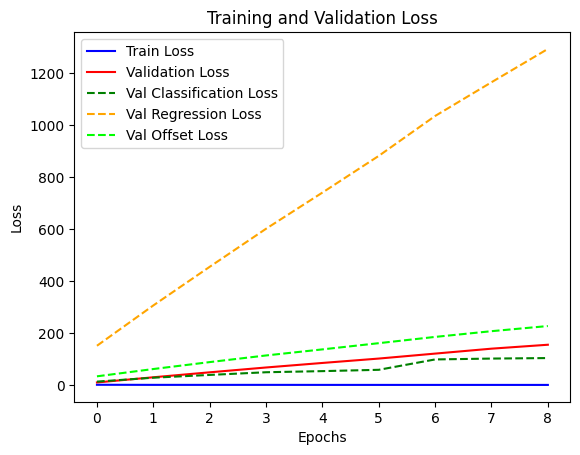

In [17]:
# Plot training/validation loss
plt.figure()
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="red")
plt.plot(val_C_losses, label='Val Classification Loss', color='green',linestyle='dashed')
plt.plot(val_R_losses, label='Val Regression Loss', color='orange',linestyle='dashed')
plt.plot(val_offset_losses, label='Val Offset Loss',color='lime',linestyle='dashed')


#plt.plot(val_C_accuracies, label="Validation Classification Accuracy", color="green")
#plt.plot(val_R_accuracies, label="Validation Regression Accuracy", color='orange')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [18]:
# showing beginning and end mse values for each parameter:

for name in param_names:
    print(f"{name:8s} MSE: Start = {param_mse_array[0,param_names.index(name)]}, End = {param_mse_array[-1,param_names.index(name)]}")


for name in param_names:
    print(f"{name:8s} MAE: Start = {param_mae_array[0,param_names.index(name)]}, End = {param_mae_array[-1,param_names.index(name)]}")


# Note: an MSE of 1 means it will always predict the mean, which means the MSE will equal the varience of the parameter (1 for normalised parameters).

T_ratio  MSE: Start = 0.5567178726196289, End = 0.3220863938331604
T1       MSE: Start = 0.9646043181419373, End = 0.8506977558135986
q        MSE: Start = 0.6611464023590088, End = 0.5424617528915405
m1       MSE: Start = 1.0522226095199585, End = 1.0853990316390991
period   MSE: Start = 0.989192008972168, End = 1.0037827491760254
Omega1   MSE: Start = 0.7158836722373962, End = 0.5089581608772278
Omega2   MSE: Start = 0.8149047493934631, End = 0.6181694269180298
e        MSE: Start = 0.30847686529159546, End = 0.20084817707538605
T_ratio  MAE: Start = 0.5265046954154968, End = 0.3691524863243103
T1       MAE: Start = 0.8355599641799927, End = 0.7786590456962585
q        MAE: Start = 0.669180154800415, End = 0.5886086821556091
m1       MAE: Start = 0.8994313478469849, End = 0.9099499583244324
period   MAE: Start = 0.865549623966217, End = 0.8530316948890686
Omega1   MAE: Start = 0.6738594174385071, End = 0.582724928855896
Omega2   MAE: Start = 0.7149428129196167, End = 0.62322574853897

(9, 8)
['T_ratio', 'T1', 'q', 'm1', 'period', 'Omega1', 'Omega2', 'e']


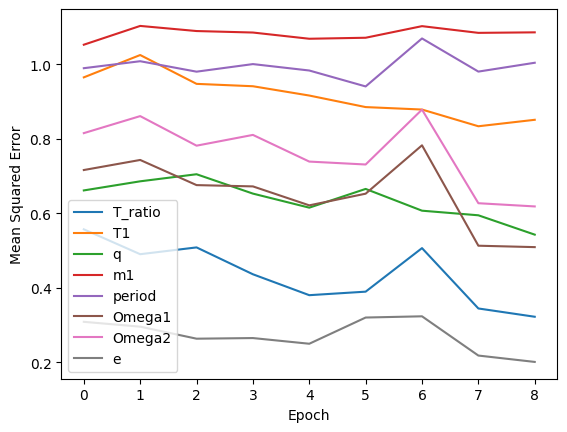

In [19]:
# plotting individual parameter mean squared errors
print(param_mse_array.shape)
print(param_names)

plt.figure()
for i in range(param_mse_array.shape[1]):
    plt.plot(range(param_mse_array.shape[0]), param_mse_array[:,i],label=param_names[i])

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()

(9, 8)
['T_ratio', 'T1', 'q', 'm1', 'period', 'Omega1', 'Omega2', 'e']


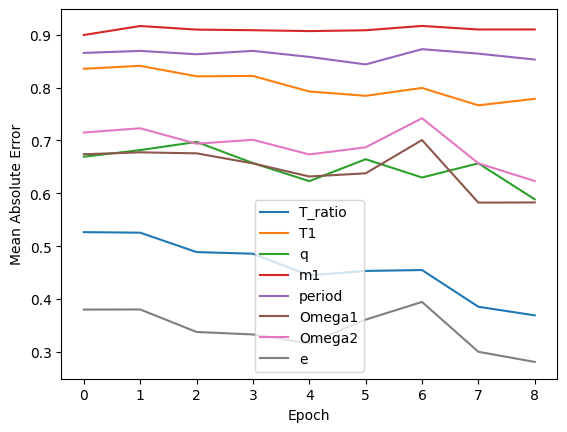

In [20]:
# plotting individual parameter mean absolute errors
print(param_mae_array.shape)
print(param_names)

plt.figure()
for i in range(param_mae_array.shape[1]):
    plt.plot(range(param_mae_array.shape[0]), param_mae_array[:,i],label=param_names[i])
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()